In [3]:
# Student Performance Prediction Using Machine Learning
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Step 2: Load the Dataset

df = pd.read_csv('student-mat.csv', sep=';')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
# Step 3: Understand the Dataset

print("Dataset Information:")
df.info()

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-nu

In [6]:
# Step 4: Check Missing Values and Duplicates

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nTotal Duplicate Rows:")
print(df.duplicated().sum())

Missing Values in Each Column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total Missing Values:
0

Total Duplicate Rows:
0


In [7]:
# Step 5: Statistical Summary of Numerical Data

display(df.describe())

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [8]:
# Step 6: Identify Categorical Columns

categorical_columns = df.select_dtypes(include=['object', 'str']).columns

print("Categorical Columns:")
print(list(categorical_columns))

print("\nTotal Categorical Columns:", len(categorical_columns))

Categorical Columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Total Categorical Columns: 17


In [9]:
# Step 7: Analyze the Target Variable

print("Final Grade (G3) Statistics:")
print(df['G3'].describe())

print("\nUnique Final Grades:")
print(sorted(df['G3'].unique()))

print("\nFrequency of Each Final Grade:")
print(df['G3'].value_counts().sort_index())

Final Grade (G3) Statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Unique Final Grades:
[np.int64(0), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]

Frequency of Each Final Grade:
G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


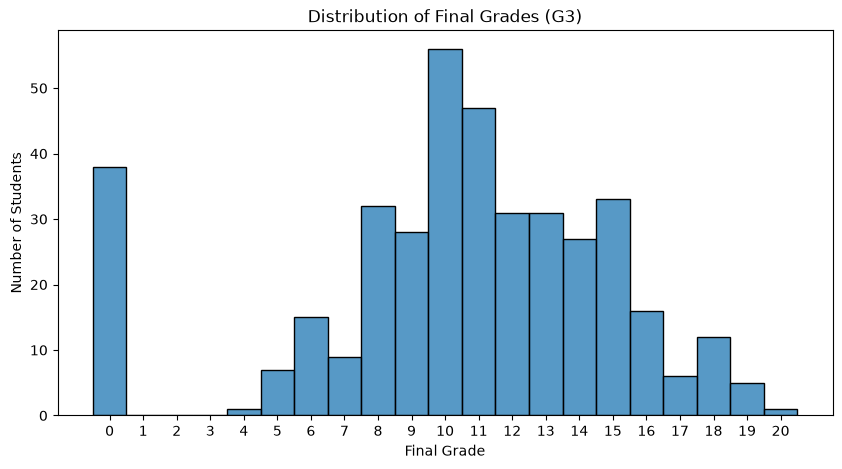

In [10]:
# Step 8: Visualize the Distribution of Final Grades

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='G3',
    bins=21,
    discrete=True
)

plt.title('Distribution of Final Grades (G3)')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.xticks(range(0, 21))
plt.show()

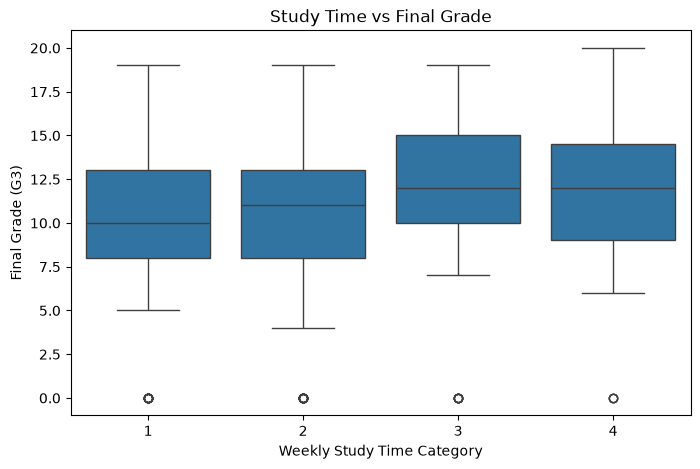

In [11]:
# Step 9: Study Time vs Final Grade

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='studytime',
    y='G3'
)

plt.title('Study Time vs Final Grade')
plt.xlabel('Weekly Study Time Category')
plt.ylabel('Final Grade (G3)')
plt.show()


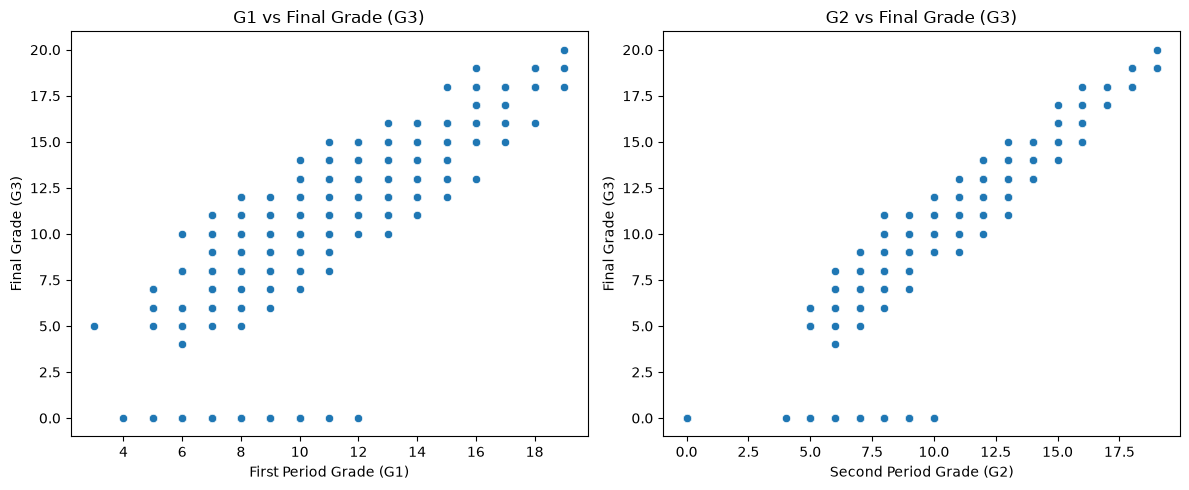

In [12]:
# Step 10: Previous Grades vs Final Grade

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x='G1', y='G3', ax=axes[0])
axes[0].set_title('G1 vs Final Grade (G3)')
axes[0].set_xlabel('First Period Grade (G1)')
axes[0].set_ylabel('Final Grade (G3)')

sns.scatterplot(data=df, x='G2', y='G3', ax=axes[1])
axes[1].set_title('G2 vs Final Grade (G3)')
axes[1].set_xlabel('Second Period Grade (G2)')
axes[1].set_ylabel('Final Grade (G3)')

plt.tight_layout()
plt.show()

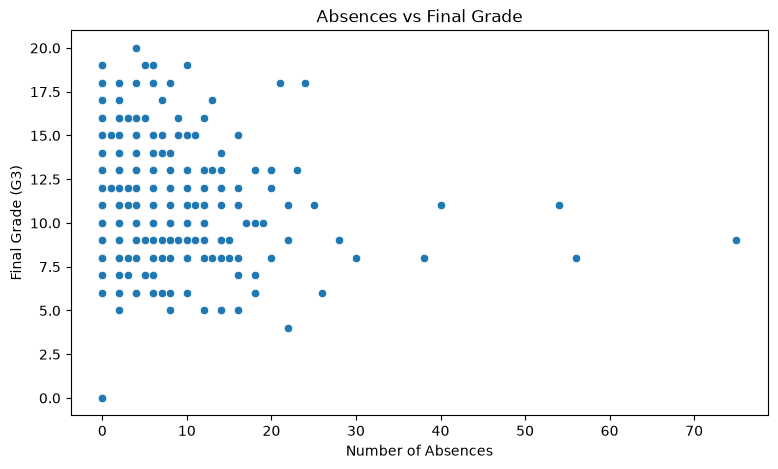

In [13]:
# Step 11: Analyze Absences vs Final Grade

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='absences',
    y='G3'
)

plt.title('Absences vs Final Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade (G3)')
plt.show()


In [14]:
# Step 12: Correlation Analysis

correlation = df.corr(numeric_only=True)

g3_correlation = correlation['G3'].sort_values(ascending=False)

print("Correlation of Features with Final Grade (G3):")
display(g3_correlation)

Correlation of Features with Final Grade (G3):


G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64

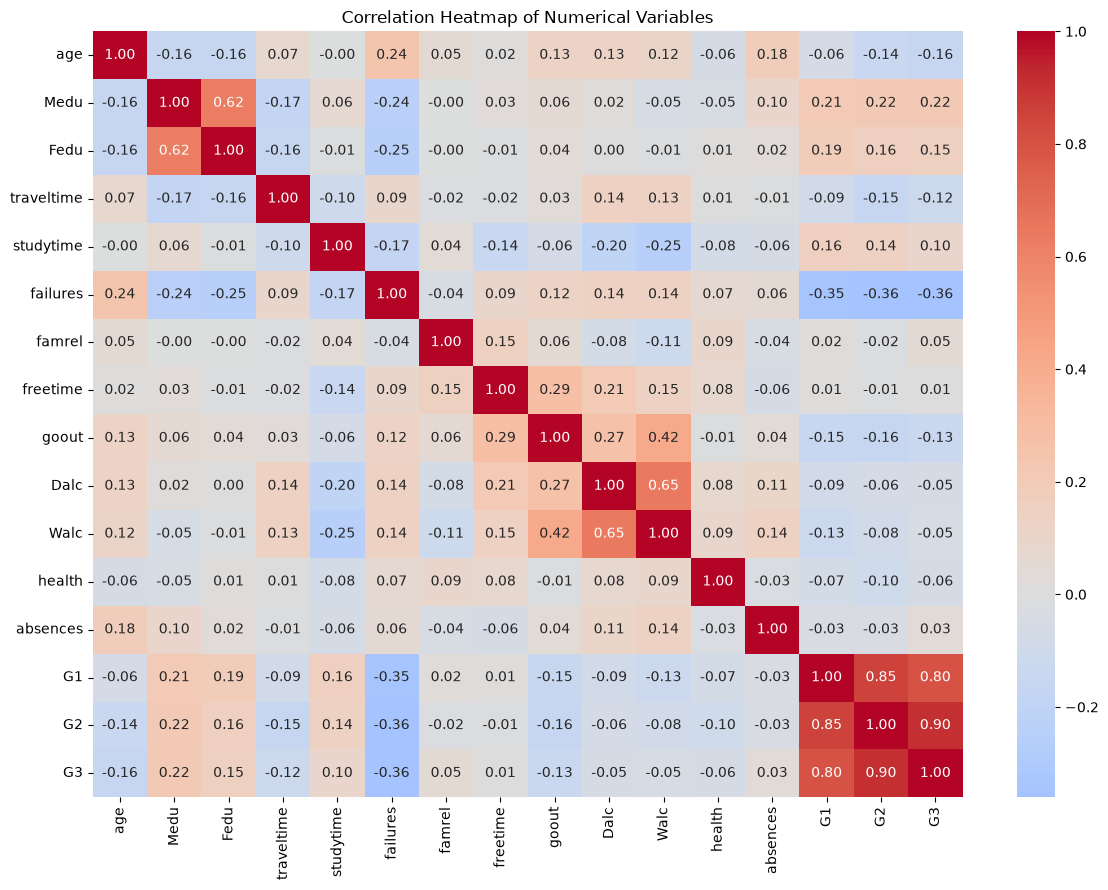

In [15]:
# Step 13: Correlation Heatmap

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

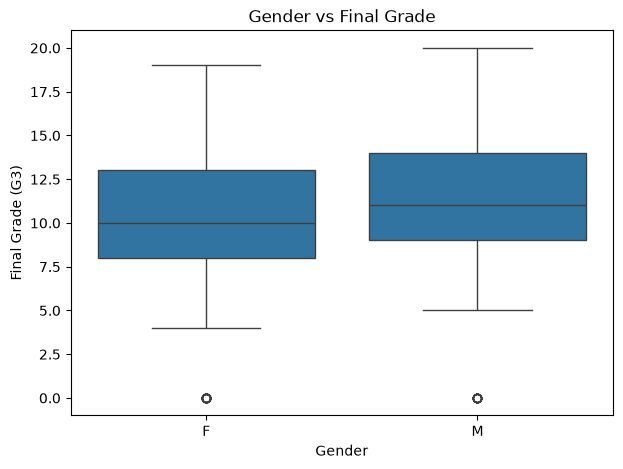

In [16]:
# Step 14: Gender vs Final Grade

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='sex',
    y='G3'
)

plt.title('Gender vs Final Grade')
plt.xlabel('Gender')
plt.ylabel('Final Grade (G3)')
plt.show()

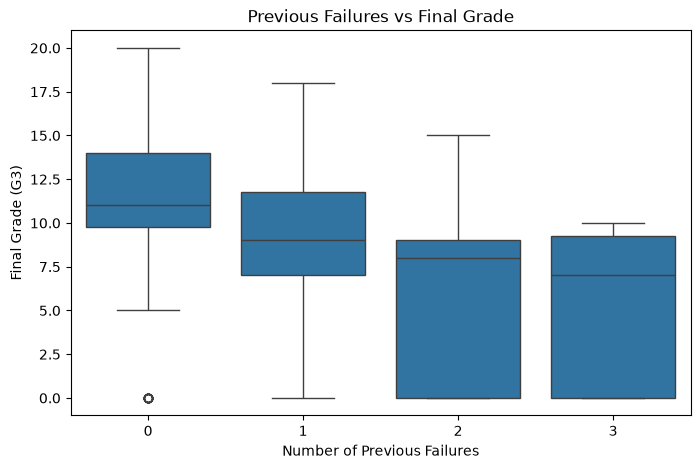

In [17]:
# Step 15: Previous Failures vs Final Grade

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='failures',
    y='G3'
)

plt.title('Previous Failures vs Final Grade')
plt.xlabel('Number of Previous Failures')
plt.ylabel('Final Grade (G3)')
plt.show()

In [18]:
# Step 16: Identify Numerical and Categorical Features

numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = df.select_dtypes(
    include=['object', 'str']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [19]:
# Step 17: Separate Features and Target

X = df.drop('G3', axis=1)
y = df['G3']

print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

print("\nTarget Column:", y.name)

Input Features (X): (395, 32)
Target Variable (y): (395,)

Target Column: G3


In [20]:
# Step 18: Encode Categorical Features

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)

print("Original Features Shape:", X.shape)
print("Encoded Features Shape:", X_encoded.shape)

display(X_encoded.head())

Original Features Shape: (395, 32)
Encoded Features Shape: (395, 41)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,True,False,True,False,False,False,True,True,False,False
1,17,1,1,1,2,0,5,3,3,1,...,False,False,False,True,False,False,False,True,True,False
2,15,1,1,1,2,3,4,3,2,2,...,True,False,True,False,True,False,True,True,True,False
3,15,4,2,1,3,0,3,2,2,1,...,True,False,False,True,True,True,True,True,True,True
4,16,3,3,1,2,0,4,3,2,1,...,False,False,False,True,True,False,True,True,False,False


In [21]:
# Step 19: Split Data into Training and Testing Sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (316, 41)
Testing Features: (79, 41)
Training Target: (316,)
Testing Target: (79,)


In [22]:
# Step 20: Train the Linear Regression Model

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [23]:
# Step 21: Make Predictions

y_pred = linear_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Grades:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Grades:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Actual Grades:
[10 12  5 10  9 13 18  6  0 14]

First 10 Predicted Grades:
[ 6.00160699 11.52847844  2.86643677  8.79663116  8.55310627 11.88964112
 19.09674195  7.17307901  7.4050707  12.31153657]


In [24]:
# Step 22: Evaluate Linear Regression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Evaluation")
print("-----------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Model Evaluation
-----------------------------------
MAE: 1.6466656197147518
RMSE: 2.378369784796138
R2 Score: 0.7241341236974019


In [25]:
# Step 23: Train Random Forest Regression Model

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Regression model trained successfully!")

Random Forest Regression model trained successfully!


In [26]:
# Step 24: Evaluate Random Forest Model

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Evaluation")
print("--------------------------------")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Model Evaluation
--------------------------------
MAE: 1.1734177215189876
RMSE: 1.9666317668361595
R2 Score: 0.8113810489794643


In [27]:
# Step 25: Compare Both Models

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae, rf_mae],
    'RMSE': [rmse, rf_rmse],
    'R2 Score': [r2, rf_r2]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.646666,2.378370,0.724134
1,Random Forest,1.173418,1.966632,0.811381


In [28]:
print("PROJECT CONCLUSION")
print("------------------")
print("1. Student Performance Prediction was completed using Machine Learning.")
print("2. Two models were trained: Linear Regression and Random Forest.")
print("3. Linear Regression R2 Score:", round(r2, 4))
print("4. Random Forest R2 Score:", round(rf_r2, 4))
print("5. Random Forest performed better on the test dataset.")
print("6. Previous grades G1 and G2 were strongly related to the final grade G3.")

PROJECT CONCLUSION
------------------
1. Student Performance Prediction was completed using Machine Learning.
2. Two models were trained: Linear Regression and Random Forest.
3. Linear Regression R2 Score: 0.7241
4. Random Forest R2 Score: 0.8114
5. Random Forest performed better on the test dataset.
6. Previous grades G1 and G2 were strongly related to the final grade G3.
